In [2]:
%pip install geopandas -q

StatementMeta(, 9350cbc8-9c06-4c58-b5b4-359f22b4d47f, 8, Finished, Available, Finished, True)


Note: you may need to restart the kernel to use updated packages.



StatementMeta(, 9350cbc8-9c06-4c58-b5b4-359f22b4d47f, 10, Finished, Available, Finished, False)

mistral_toulon  jour de référence 2026-11-03 | 2013 arrêts desservis
rtm_marseille   jour de référence 2026-11-03 | 2740 arrêts desservis
zou_trains      jour de référence 2026-12-29 | 9 arrêts desservis
sncf_trains     jour de référence 2026-11-03 | 4462 arrêts desservis
levelo_marseille  stations :  228 | véhicules en libre accès : 0
Sauvegardé : tables 'arrets' et 'vehicules_libres' dans lakehouse_silver


/tmp/ipykernel_6769/4238588253.py:123: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  arrets = garder_villes(gpd.GeoDataFrame(pd.concat([gtfs[cols]] + [s[cols] for s in stations], ignore_index=True), crs=4326))


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

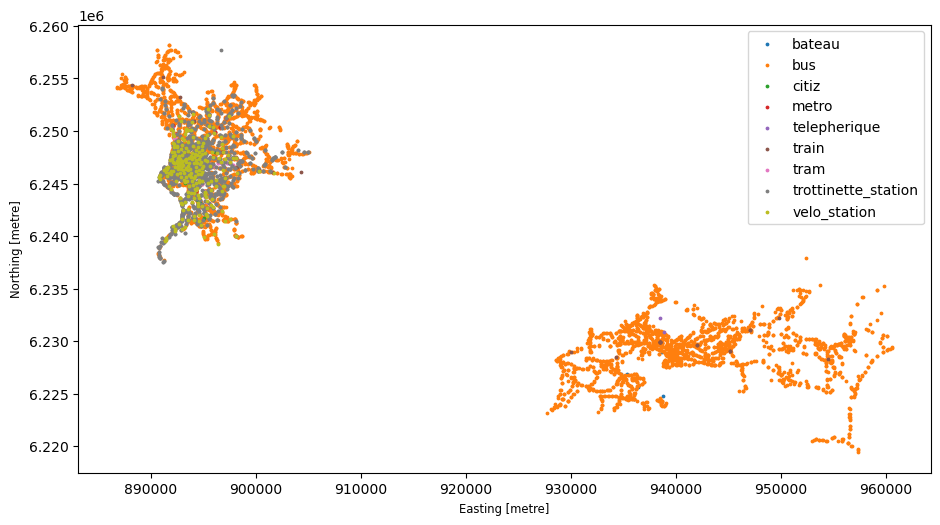

In [3]:
import geopandas as gpd, pandas as pd, glob, json, os

# ---------- Paramètres ----------
BRONZE = "/lakehouse/default/Files"
notebookutils.fs.mount("abfss://citiz_hackathon@onelake.dfs.fabric.microsoft.com/lakehouse_silver.Lakehouse", "/silver")
SILVER = notebookutils.fs.getMountPath("/silver") + "/Files/arrets"
os.makedirs(SILVER, exist_ok=True)

tpm = gpd.read_file("https://geo.api.gouv.fr/epcis/248300543/communes?fields=nom,code,contour&format=geojson&geometry=contour")
mrs = gpd.read_file("https://geo.api.gouv.fr/communes?code=13055&fields=nom,code,contour&format=geojson&geometry=contour")
ZONES = {"toulon": tpm.to_crs(2154).union_all().buffer(1000),
         "marseille": mrs.to_crs(2154).union_all().buffer(1000)}

def garder_villes(gdf):
    gdf = gdf.to_crs(2154).copy()
    gdf["ville"] = None
    for v, z in ZONES.items():
        gdf.loc[gdf.ville.isna() & gdf.within(z), "ville"] = v
    return gdf[gdf.ville.notna()]

# ---------- 1. Transports en commun (GTFS) ----------
def mode_de(rt):
    rt = int(rt)
    simple = {0: "tram", 1: "metro", 2: "train", 3: "bus", 4: "bateau", 5: "tram", 6: "telepherique", 7: "funiculaire", 11: "bus", 12: "train"}
    if rt < 100: return simple.get(rt, "bus")
    if rt < 200: return "train"
    if 400 <= rt < 500: return "metro"
    if 900 <= rt < 1000: return "tram"
    if 1000 <= rt < 1100 or rt == 1200: return "bateau"
    if 1300 <= rt < 1400: return "telepherique"
    if rt == 1400: return "funiculaire"
    return "bus"
PRIORITE = ["train", "metro", "tram", "bateau", "telepherique", "funiculaire", "bus"]

def lire(d, f, **kw):
    p = f"{d}/{f}.txt"
    return pd.read_csv(p, dtype=str, encoding="utf-8-sig", **kw) if os.path.exists(p) else None

def services_actifs(cal, cd, jour):
    ds, nom_jour = jour.strftime("%Y%m%d"), jour.strftime("%A").lower()
    s = set()
    if cal is not None:
        s = set(cal.loc[(cal.start_date <= ds) & (cal.end_date >= ds) & (cal[nom_jour] == "1"), "service_id"])
    if cd is not None:
        e = cd[cd.date == ds]
        s |= set(e.loc[e.exception_type == "1", "service_id"])
        s -= set(e.loc[e.exception_type == "2", "service_id"])
    return s

def arrets_gtfs(reseau):
    d = f"{BRONZE}/transports/{reseau}"
    stops = lire(d, "stops")
    if "location_type" in stops:
        stops = stops[stops.location_type.fillna("0").isin(["0", ""])]
    trips  = lire(d, "trips", usecols=["trip_id", "route_id", "service_id"])
    routes = lire(d, "routes", usecols=["route_id", "route_type"])
    cal, cd = lire(d, "calendar"), lire(d, "calendar_dates")

    # jour de référence = le mardi avec le plus de courses
    debut = min(cal.start_date) if cal is not None and len(cal) else min(cd.date)
    fin   = max(cal.end_date)   if cal is not None and len(cal) else max(cd.date)
    mardis = [j for j in pd.date_range(debut, fin) if j.weekday() == 1][:20]
    jour = max(mardis, key=lambda j: trips.service_id.isin(services_actifs(cal, cd, j)).sum())
    actifs = services_actifs(cal, cd, jour)

    t = trips[trips.service_id.isin(actifs)].merge(routes, on="route_id")
    t["mode"] = t.route_type.map(mode_de)
    st = lire(d, "stop_times", usecols=["trip_id", "stop_id", "departure_time"]).merge(t[["trip_id", "mode"]], on="trip_id")
    h = st.departure_time.fillna("").str.zfill(8)

    out = stops[["stop_id", "stop_name", "stop_lat", "stop_lon"]].copy()
    out["departs_heure_pointe"] = out.stop_id.map(st[(h >= "07:00:00") & (h < "09:00:00")].groupby("stop_id").size() / 2).fillna(0)
    out["departs_jour"] = out.stop_id.map(st.groupby("stop_id").size()).fillna(0)
    out["type"] = out.stop_id.map(st.groupby("stop_id")["mode"].agg(lambda m: min(m, key=PRIORITE.index)))
    out = out[out.departs_jour > 0]
    print(f"{reseau:15s} jour de référence {jour.date()} | {len(out)} arrêts desservis")
    g = gpd.GeoDataFrame(out, geometry=gpd.points_from_xy(out.stop_lon.astype(float), out.stop_lat.astype(float)), crs=4326)
    return g.assign(arret_id=reseau + ":" + g.stop_id, nom=g.stop_name, source=reseau, capacite=None)

gtfs = pd.concat([arrets_gtfs(r) for r in ["mistral_toulon", "rtm_marseille", "zou_trains", "sncf_trains"]])

# ---------- 2. Vélos / trottinettes (GBFS) ----------
def dernier(d, flux):
    f = sorted(glob.glob(f"{d}/{flux}_*.json"))
    return json.load(open(f[-1])) if f else None

def texte(v):
    return v[0]["text"] if isinstance(v, list) and v and isinstance(v[0], dict) else v

stations, libres = [], []
for op in ["levelo_marseille", "voi_marseille", "lime_marseille", "pony_marseille"]:
    d = f"{BRONZE}/transports/{op}"
    info = dernier(d, "station_information")
    st = pd.DataFrame(info["data"].get("stations", [])) if info else pd.DataFrame()
    if len(st):
        stations.append(gpd.GeoDataFrame({
            "arret_id": op + ":" + st.station_id.astype(str),
            "nom": st["name"].apply(texte) if "name" in st else "",
            "type": "velo_station" if op.startswith("levelo") else "trottinette_station", "source": op,
            "capacite": st["capacity"] if "capacity" in st else None,
            "departs_heure_pointe": None, "departs_jour": None},
            geometry=gpd.points_from_xy(st.lon, st.lat), crs=4326))
    fb = dernier(d, "free_bike_status")
    vb = pd.DataFrame(fb["data"].get("bikes", fb["data"].get("vehicles", []))) if fb else pd.DataFrame()
    if len(vb) and {"lat", "lon"} <= set(vb.columns):
        if "station_id" in vb:
            vb = vb[vb.station_id.isna()]
        libres.append(gpd.GeoDataFrame({"operateur": op}, index=vb.index, geometry=gpd.points_from_xy(vb.lon, vb.lat), crs=4326))
    print(f"{op:17s} stations : {len(st):4d} | véhicules en libre accès : {len(vb)}")

# ---------- 3. Citiz Marseille ----------
d = f"{BRONZE}/citiz/citiz_marseille"
ci = pd.DataFrame(dernier(d, "station_information")["data"]["stations"])
nb_voitures = pd.DataFrame(dernier(d, "vehicle_status")["data"]["vehicles"]).groupby("station_id").size()
stations.append(gpd.GeoDataFrame({
    "arret_id": "citiz:" + ci.station_id.astype(str), "nom": ci["name"].apply(texte), "type": "citiz", "source": "citiz_marseille",
    "capacite": ci.station_id.map(nb_voitures).fillna(0), "departs_heure_pointe": None, "departs_jour": None},
    geometry=gpd.points_from_xy(ci.lon, ci.lat), crs=4326))
print("citiz_marseille   stations :", len(ci), "| voitures :", int(nb_voitures.sum()))

# ---------- 4. Tout réunir, garder Toulon + Marseille ----------
cols = ["arret_id", "nom", "type", "source", "departs_heure_pointe", "departs_jour", "capacite", "geometry"]
arrets = garder_villes(gpd.GeoDataFrame(pd.concat([gtfs[cols]] + [s[cols] for s in stations], ignore_index=True), crs=4326))
for c in ["departs_heure_pointe", "departs_jour", "capacite"]:
    arrets[c] = pd.to_numeric(arrets[c], errors="coerce")

# ---------- 5. Sauvegarder dans lakehouse_silver ----------
arrets.to_parquet(f"{SILVER}/arrets_toulon_marseille.parquet")
def vers_table(gdf, nom):
    t = pd.DataFrame(gdf.drop(columns="geometry"))
    p = gdf.to_crs(4326).geometry
    t["lon"], t["lat"] = p.x, p.y
    for c in t.columns:
        if t[c].dtype == object: t[c] = t[c].astype(str)
    sdf = spark.createDataFrame(t)
    try:    sdf.write.mode("overwrite").option("overwriteSchema", "true").saveAsTable(f"lakehouse_silver.dbo.{nom}")
    except Exception: sdf.write.mode("overwrite").option("overwriteSchema", "true").saveAsTable(f"lakehouse_silver.{nom}")
vers_table(arrets, "arrets")
if libres:
    lib = garder_villes(gpd.GeoDataFrame(pd.concat(libres, ignore_index=True), crs=4326))
    lib.to_parquet(f"{SILVER}/vehicules_libres_marseille.parquet")
    vers_table(lib, "vehicules_libres")
print("Sauvegardé : tables 'arrets' et 'vehicules_libres' dans lakehouse_silver")

# ---------- 6. Carte ----------
arrets.plot(column="type", legend=True, markersize=3, figsize=(11, 7))

In [4]:
print(arrets.pivot_table(index="type", columns="ville", values="arret_id", aggfunc="count", fill_value=0))
print("\nDéparts à l'heure de pointe (somme) :")
print(arrets.groupby("ville")["departs_heure_pointe"].sum().round(0))

StatementMeta(, 9350cbc8-9c06-4c58-b5b4-359f22b4d47f, 11, Finished, Available, Finished, False)

ville                marseille  toulon
type                                  
bateau                       2       8
bus                       2469    2003
citiz                       91       0
metro                       61       0
telepherique                 0       2
train                       18      16
tram                        89       0
trottinette_station       2558       0
velo_station               228       0

Départs à l'heure de pointe (somme) :
ville
marseille    20691.0
toulon        9436.0
Name: departs_heure_pointe, dtype: float64
